# Netflix Content Analysis: What is in the catalogue?

**Data Science Mini Project** | Exploratory data analysis of Netflix Movies and TV Shows

**Dataset:** 7,787 Netflix titles (movies and TV shows) with type, country, genres, rating, release year, date added and duration.
Source: the Kaggle dataset *Netflix Movies and Television Shows* (by Shivam Bansal), mirrored in the TidyTuesday repository (2021-04-20).

**Questions this notebook answers**
1. How is the catalogue split between movies and TV shows?
2. How has the pace of new additions changed over the years?
3. Which countries, genres and audience ratings dominate?
4. How long are movies, and how many seasons do TV shows run?
5. When are titles added, and how old are they when they arrive?
6. How does India compare with the other big contributors?

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
import warnings
warnings.filterwarnings("ignore")

# One colour per entity, used consistently: Movie = blue, TV Show = orange
BLUE, ORANGE, LIGHT_BLUE, DARK_BLUE = "#2a78d6", "#eb6834", "#a9c8f0", "#0f3d7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
TYPE_COLORS = {"Movie": BLUE, "TV Show": ORANGE}
SEQ = LinearSegmentedColormap.from_list("blue_seq", ["#eaf1fb", BLUE, DARK_BLUE])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "legend.frameon": False, "font.size": 10,
})

os.makedirs("images", exist_ok=True)
def save(fig, name):
    fig.savefig(f"images/{name}.png", bbox_inches="tight")

## 1. Load the data

In [2]:
df = pd.read_csv("data/netflix_titles.csv")
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

7,787 rows x 12 columns


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-coun...


In [3]:
missing = (df.isna().sum().to_frame("missing")
             .assign(pct=lambda d: (d["missing"] / len(df) * 100).round(1))
             .query("missing > 0")
             .sort_values("missing", ascending=False))
print("Duplicate show_id values:", df.duplicated("show_id").sum())
print("Duplicate (title, type, release_year):", df.duplicated(["title", "type", "release_year"]).sum())
missing

Duplicate show_id values: 0
Duplicate (title, type, release_year): 0


,missing,pct
director,2389,30.7
cast,718,9.2
country,507,6.5
date_added,10,0.1
rating,7,0.1


## 2. Clean the data

Decisions, and why:
- **Missing `director`, `cast`, `country`, `rating`** are filled with `"Unknown"`. Dropping them would remove up to 31% of titles (director) that are still valid for other questions.
- **Missing `date_added`** (10 rows) stays empty; those rows are left out only of the questions that need the date.
- **`date_added`** is text like "August 14, 2020", so it is converted to a real date; year and month are extracted.
- **`duration`** mixes minutes (movies) and seasons (TV shows), so it is split into two numeric columns.
- **`country` and `listed_in`** hold several comma-separated values. For country comparisons the **first listed country** is used as the primary one; for genres every listed genre is counted.
- **`rating`** has 14 codes, which are grouped into five audience groups so they can be compared across movies and TV.

In [4]:
df = df.copy()
for c in ["title", "director", "cast", "country", "rating", "listed_in", "duration"]:
    df[c] = df[c].str.strip()

df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), format="%B %d, %Y", errors="coerce")
df["year_added"] = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month_name()

for c in ["director", "cast", "country", "rating"]:
    df[c] = df[c].fillna("Unknown")

df["primary_country"] = df["country"].str.split(",").str[0].str.strip()

num = df["duration"].str.extract(r"(\d+)")[0].astype(float)
df["minutes"] = np.where(df["type"] == "Movie", num, np.nan)
df["seasons"] = np.where(df["type"] == "TV Show", num, np.nan)

AUDIENCE = {"TV-Y": "Kids", "TV-Y7": "Kids", "TV-Y7-FV": "Kids", "TV-G": "Kids", "G": "Kids",
            "TV-PG": "Older kids / family", "PG": "Older kids / family",
            "TV-14": "Teens", "PG-13": "Teens",
            "TV-MA": "Adults", "R": "Adults", "NC-17": "Adults",
            "NR": "Not rated", "UR": "Not rated", "Unknown": "Not rated"}
AUD_ORDER = ["Kids", "Older kids / family", "Teens", "Adults", "Not rated"]
df["audience"] = df["rating"].map(AUDIENCE).fillna("Not rated")

# One row per (title, genre) for genre questions
genres = df.assign(genre=df["listed_in"].str.split(",")).explode("genre").reset_index(drop=True)
genres["genre"] = genres["genre"].str.strip()
# "International ..." only means "not from the US", so it is kept out of genre rankings
region_tags = {"International Movies", "International TV Shows"}

print("Latest date_added in the data:", df["date_added"].max().date())
print("Rating codes not mapped to an audience group:", sorted(set(df["rating"]) - set(AUDIENCE)))
print("Remaining missing values (excluding the 'Unknown' fills):")
print(df[["date_added", "minutes", "seasons"]].isna().sum())

Latest date_added in the data: 2021-01-16
Rating codes not mapped to an audience group: []
Remaining missing values (excluding the 'Unknown' fills):
date_added      10
minutes       2410
seasons       5377
dtype: int64


## 3. Exploratory analysis

### 3.1 Movies vs TV shows

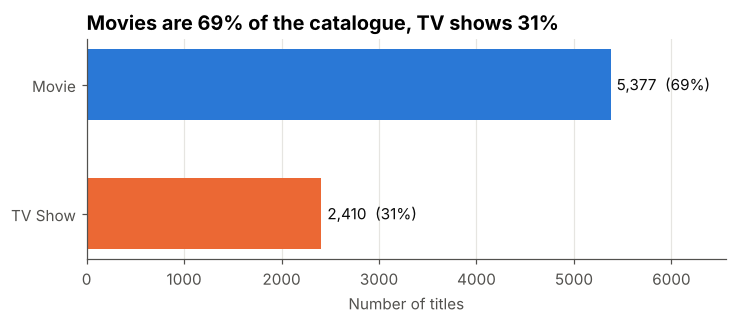

In [5]:
type_counts = df["type"].value_counts()
share = type_counts / len(df)

fig, ax = plt.subplots(figsize=(7.5, 2.6))
order = type_counts.index[::-1]
bars = ax.barh(order, type_counts[order].values, color=[TYPE_COLORS[t] for t in order], height=0.55)
for b, v in zip(bars, type_counts[order].values):
    ax.text(v + 60, b.get_y() + b.get_height() / 2, f"{v:,}  ({v / len(df):.0%})", va="center", color=INK)
ax.set_xlim(0, type_counts.max() * 1.22)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Number of titles")
ax.set_title(f"Movies are {share['Movie']:.0%} of the catalogue, TV shows {share['TV Show']:.0%}")
save(fig, "01_type_split"); plt.show()

### 3.2 How fast is Netflix adding titles?

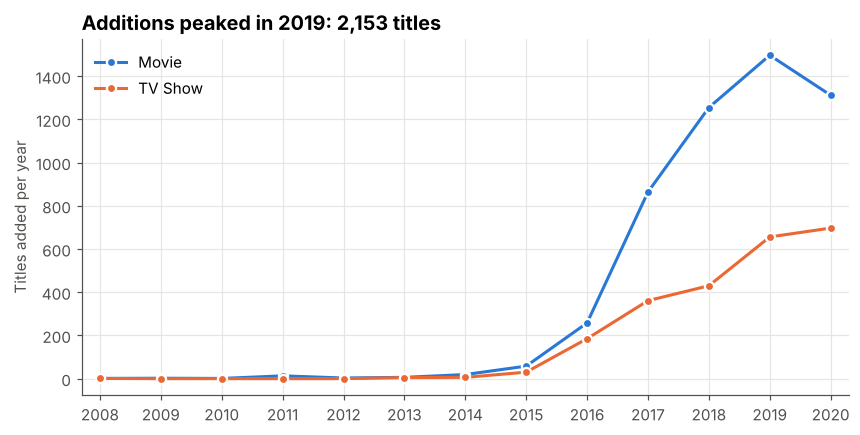

(2021 excluded: data only runs to 2021-01-16)
type        Movie  TV Show  total
year_added                       
2013            6        5     11
2014           19        6     25
2015           58       30     88
2016          258      185    443
2017          864      361   1225
2018         1255      430   1685
2019         1497      656   2153
2020         1312      697   2009


In [6]:
partial_year = df["date_added"].max().year          # latest year is incomplete, so exclude it
added = (df.dropna(subset=["year_added"])
           .groupby(["year_added", "type"]).size().unstack(fill_value=0))
added.index = added.index.astype(int)
added = added[added.index < partial_year]
total_added = added.sum(axis=1)
peak_year = total_added.idxmax()

fig, ax = plt.subplots(figsize=(9, 4.2))
for t in ["Movie", "TV Show"]:
    ax.plot(added.index, added[t], color=TYPE_COLORS[t], lw=2, marker="o", ms=6,
            markeredgecolor="white", markeredgewidth=1.5, label=t)
ax.set_xlim(added.index.min() - 0.3, added.index.max() + 0.3)
ax.set_xticks(added.index)
ax.set_ylabel("Titles added per year")
ax.set_title(f"Additions peaked in {peak_year}: {total_added[peak_year]:,} titles")
ax.legend(loc="upper left")
save(fig, "02_added_per_year"); plt.show()

print(f"({partial_year} excluded: data only runs to {df['date_added'].max().date()})")
print(added.assign(total=total_added).tail(8))

### 3.3 When were the titles originally released?

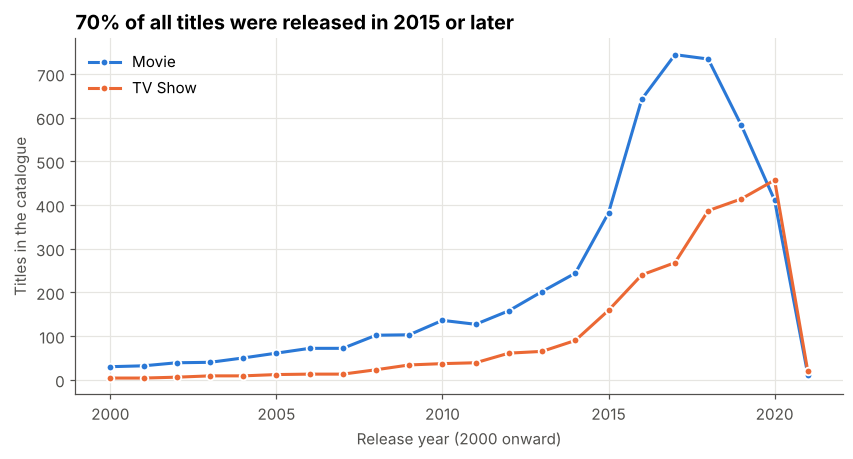

Oldest title: 1925 | Median release year: 2017
Share released before 2000: 5.8%


In [7]:
recent_share = (df["release_year"] >= 2015).mean()
rel = (df[df["release_year"] >= 2000].groupby(["release_year", "type"]).size().unstack(fill_value=0))

fig, ax = plt.subplots(figsize=(9, 4.2))
for t in ["Movie", "TV Show"]:
    ax.plot(rel.index, rel[t], color=TYPE_COLORS[t], lw=2, marker="o", ms=5,
            markeredgecolor="white", markeredgewidth=1.2, label=t)
ax.set_ylabel("Titles in the catalogue")
ax.set_xlabel("Release year (2000 onward)")
ax.set_title(f"{recent_share:.0%} of all titles were released in 2015 or later")
ax.legend(loc="upper left")
save(fig, "03_release_year"); plt.show()

print("Oldest title:", int(df["release_year"].min()), "| Median release year:", int(df["release_year"].median()))
print("Share released before 2000: {:.1%}".format((df["release_year"] < 2000).mean()))

### 3.4 Which countries produce the catalogue?

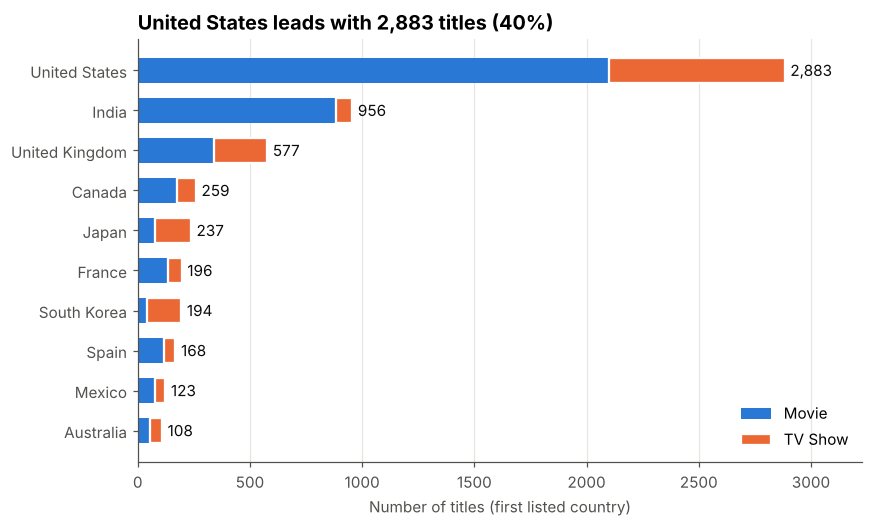

Titles with a known country: 7,280 | Unknown: 507
Top 3 countries share of known-country titles: 61%
India rank: 2 with 956 titles


In [8]:
known = df[df["primary_country"] != "Unknown"]
vc = known["primary_country"].value_counts()
top_c = vc.head(10)
tc = (known[known["primary_country"].isin(top_c.index)]
        .groupby(["primary_country", "type"]).size().unstack(fill_value=0).loc[top_c.index])

fig, ax = plt.subplots(figsize=(8.5, 5))
y = np.arange(len(tc))[::-1]
ax.barh(y, tc["Movie"], color=BLUE, height=0.62, label="Movie")
ax.barh(y, tc["TV Show"], left=tc["Movie"], color=ORANGE, height=0.62, label="TV Show",
        edgecolor="white", linewidth=1.5)
for yi, tot in zip(y, tc.sum(axis=1)):
    ax.text(tot + 25, yi, f"{tot:,}", va="center", color=INK)
ax.set_yticks(y); ax.set_yticklabels(tc.index)
ax.set_xlim(0, tc.sum(axis=1).max() * 1.12)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Number of titles (first listed country)")
ax.set_title(f"{top_c.index[0]} leads with {top_c.iloc[0]:,} titles ({top_c.iloc[0] / len(known):.0%})")
ax.legend(loc="lower right")
save(fig, "04_top_countries"); plt.show()

print("Titles with a known country:", f"{len(known):,}", "| Unknown:", f"{(df['primary_country'] == 'Unknown').sum():,}")
print(f"Top 3 countries share of known-country titles: {top_c.head(3).sum() / len(known):.0%}")
print("India rank:", vc.index.get_loc("India") + 1, "with", f"{vc['India']:,}", "titles")

### 3.5 Which genres are most common?

The regional labels "International Movies" and "International TV Shows" are the most frequent tags, but they only mean "not from the US". They are counted separately and left out of the ranking so the real genres show.

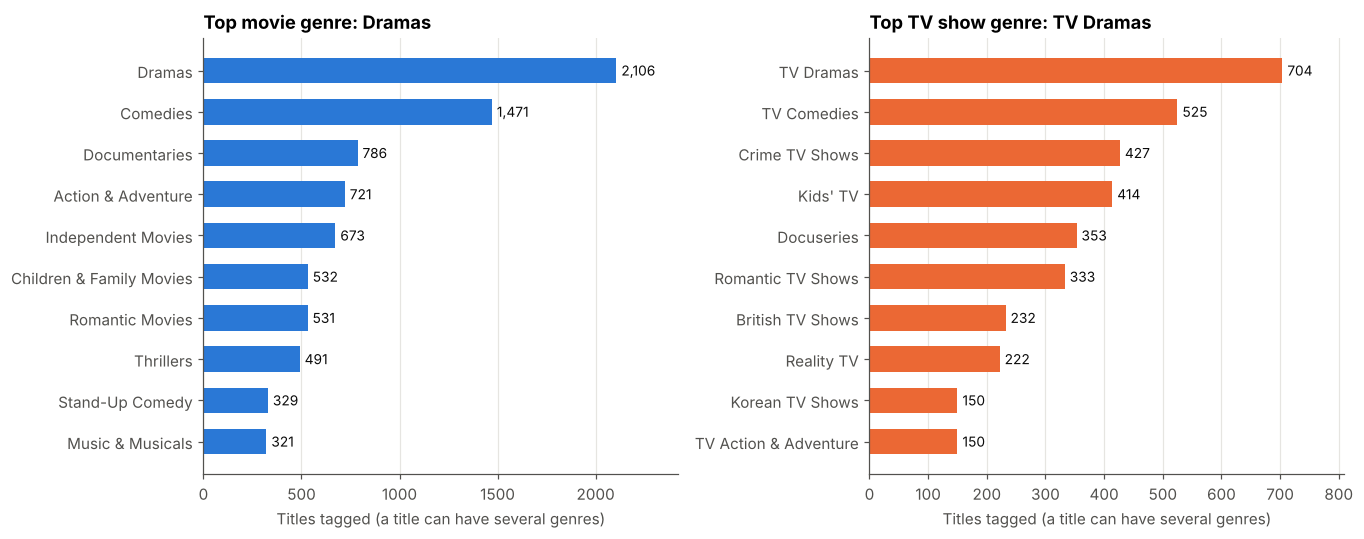

Movie: top genre is Dramas (2,106 tags)
TV Show: top genre is TV Dramas (704 tags)
International-label tags: {'International Movies': 2437, 'International TV Shows': 1199}


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
top_genre_by_type = {}
for ax, t in zip(axes, ["Movie", "TV Show"]):
    g = genres[(genres["type"] == t) & (~genres["genre"].isin(region_tags))]["genre"].value_counts().head(10)[::-1]
    top_genre_by_type[t] = (g.index[-1], g.iloc[-1])
    ax.barh(g.index, g.values, color=TYPE_COLORS[t], height=0.62)
    for i, v in enumerate(g.values):
        ax.text(v + g.max() * 0.012, i, f"{v:,}", va="center", color=INK, fontsize=9)
    ax.set_xlim(0, g.max() * 1.15)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"Top {'movie' if t == 'Movie' else 'TV show'} genre: {g.index[-1]}", fontsize=12)
    ax.set_xlabel("Titles tagged (a title can have several genres)")
plt.tight_layout()
save(fig, "05_top_genres"); plt.show()

for t, (name, n) in top_genre_by_type.items():
    print(f"{t}: top genre is {name} ({n:,} tags)")
print("International-label tags:", genres[genres["genre"].isin(region_tags)]["genre"].value_counts().to_dict())

### 3.6 Who is the content made for?

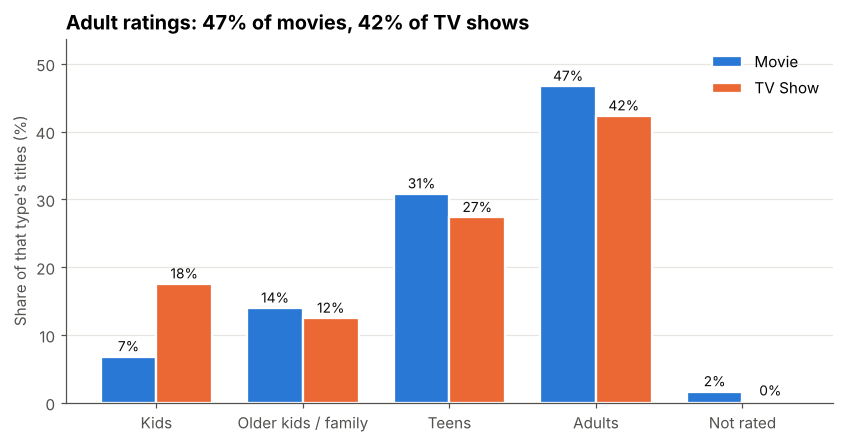

rating
TV-MA    2863
TV-14    1931
TV-PG     806
R         665
PG-13     386
Name: count, dtype: int64


In [10]:
aud = (pd.crosstab(df["audience"], df["type"], normalize="columns").reindex(AUD_ORDER) * 100)

fig, ax = plt.subplots(figsize=(9, 4.3))
x = np.arange(len(aud)); w = 0.38
ax.bar(x - w / 2, aud["Movie"], w, color=BLUE, label="Movie", edgecolor="white", linewidth=1.5)
ax.bar(x + w / 2, aud["TV Show"], w, color=ORANGE, label="TV Show", edgecolor="white", linewidth=1.5)
for xi, (m, t) in enumerate(zip(aud["Movie"], aud["TV Show"])):
    ax.text(xi - w / 2, m + 0.8, f"{m:.0f}%", ha="center", color=INK, fontsize=9)
    ax.text(xi + w / 2, t + 0.8, f"{t:.0f}%", ha="center", color=INK, fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(aud.index)
ax.set_ylabel("Share of that type's titles (%)")
ax.set_ylim(0, aud.values.max() * 1.15)
ax.grid(axis="x", visible=False)
ax.set_title(f"Adult ratings: {aud.loc['Adults', 'Movie']:.0f}% of movies, {aud.loc['Adults', 'TV Show']:.0f}% of TV shows")
ax.legend(loc="upper right")
save(fig, "06_audience"); plt.show()

print(df["rating"].value_counts().head(5))

### 3.7 How long are movies, and how many seasons do shows run?

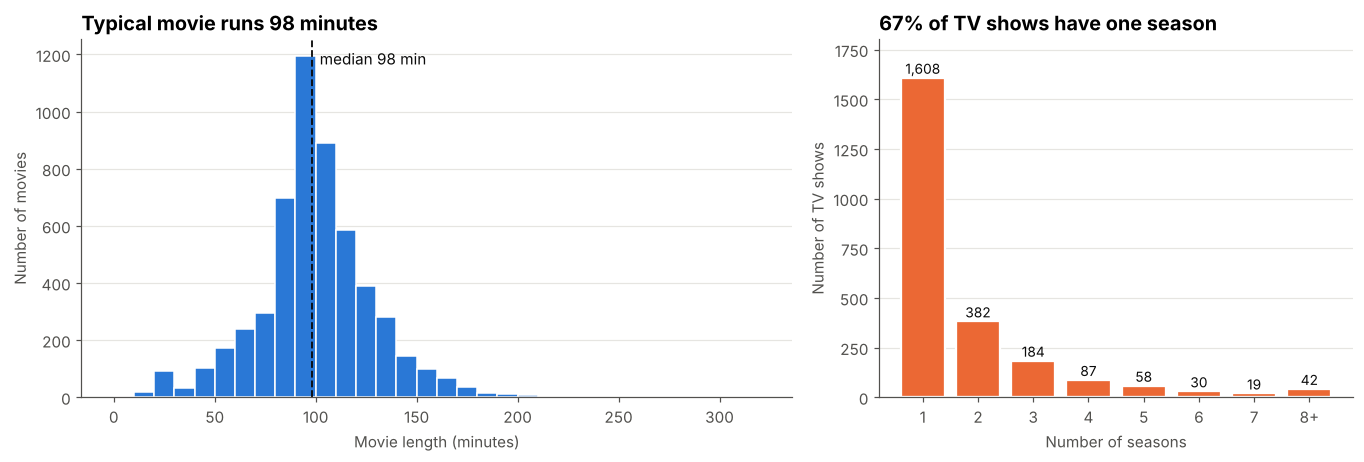

Movie length: min 3 | median 98 | max 312
Movies under 90 min: 31% | over 150 min: 4.2%
Max seasons: 16


In [11]:
movies = df[df["type"] == "Movie"]
tv = df[df["type"] == "TV Show"]
med = movies["minutes"].median()
one_season = (tv["seasons"] == 1).mean()
s = tv["seasons"].clip(upper=8).astype(int).value_counts().sort_index()
s_labels = [str(i) if i < 8 else "8+" for i in s.index]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
ax.hist(movies["minutes"].dropna(), bins=range(0, 330, 10), color=BLUE, edgecolor="white", linewidth=1)
ax.axvline(med, color=INK, ls="--", lw=1.2)
ax.text(med + 4, ax.get_ylim()[1] * 0.93, f"median {med:.0f} min", color=INK)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Movie length (minutes)"); ax.set_ylabel("Number of movies")
ax.set_title(f"Typical movie runs {med:.0f} minutes")

ax = axes[1]
bars = ax.bar(s_labels, s.values, color=ORANGE, edgecolor="white", linewidth=1.5)
for b, v in zip(bars, s.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 20, f"{v:,}", ha="center", color=INK, fontsize=9)
ax.grid(axis="x", visible=False)
ax.set_ylim(0, s.max() * 1.12)
ax.set_xlabel("Number of seasons"); ax.set_ylabel("Number of TV shows")
ax.set_title(f"{one_season:.0%} of TV shows have one season")
plt.tight_layout()
save(fig, "07_duration"); plt.show()

print("Movie length: min", int(movies["minutes"].min()), "| median", int(med), "| max", int(movies["minutes"].max()))
print("Movies under 90 min: {:.0%} | over 150 min: {:.1%}".format((movies["minutes"] < 90).mean(), (movies["minutes"] > 150).mean()))
print("Max seasons:", int(tv["seasons"].max()))

### 3.8 When do new titles arrive, and how old are they?

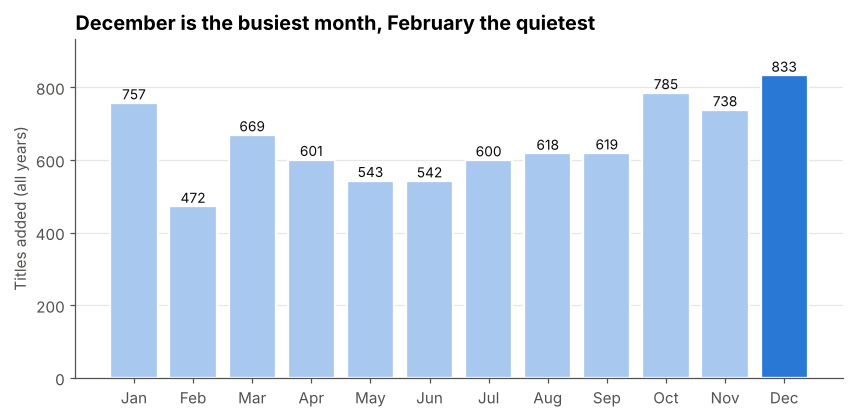

In [12]:
months = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]
m = df.dropna(subset=["date_added"])["month_added"].value_counts().reindex(months)
top_m, low_m = m.idxmax(), m.idxmin()

fig, ax = plt.subplots(figsize=(9, 4))
colors = [BLUE if mo == top_m else LIGHT_BLUE for mo in months]
bars = ax.bar([mo[:3] for mo in months], m.values, color=colors, edgecolor="white", linewidth=1.5)
for b, v in zip(bars, m.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 10, f"{v:,}", ha="center", color=INK, fontsize=9)
ax.grid(axis="x", visible=False)
ax.set_ylim(0, m.max() * 1.12)
ax.set_ylabel("Titles added (all years)")
ax.set_title(f"{top_m} is the busiest month, {low_m} the quietest")
save(fig, "08_month_added"); plt.show()

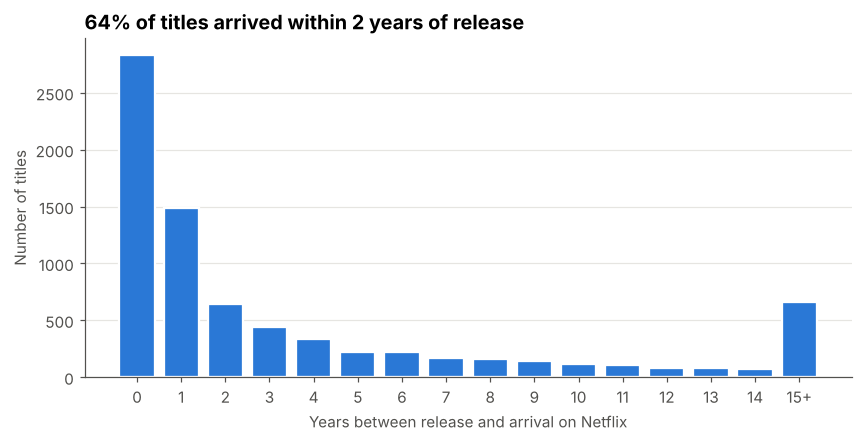

Median lag in years by type:
type
Movie      1.0
TV Show    0.0
Name: lag, dtype: float64
Titles with a negative lag (added before the release year, clipped to 0): 12


In [13]:
lag = df.dropna(subset=["year_added"]).assign(lag=lambda d: d["year_added"] - d["release_year"])
negative = (lag["lag"] < 0).sum()
lag["lag_clipped"] = lag["lag"].clip(lower=0, upper=15)
within2 = (lag["lag"] <= 2).mean()

fig, ax = plt.subplots(figsize=(9, 4))
counts = lag["lag_clipped"].astype(int).value_counts().sort_index()
labels = [str(i) if i < 15 else "15+" for i in counts.index]
ax.bar(labels, counts.values, color=BLUE, edgecolor="white", linewidth=1.5)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Years between release and arrival on Netflix"); ax.set_ylabel("Number of titles")
ax.set_title(f"{within2:.0%} of titles arrived within 2 years of release")
save(fig, "09_release_to_netflix_lag"); plt.show()

print("Median lag in years by type:")
print(lag.groupby("type")["lag"].median())
print(f"Titles with a negative lag (added before the release year, clipped to 0): {negative}")

### 3.9 Most prolific directors

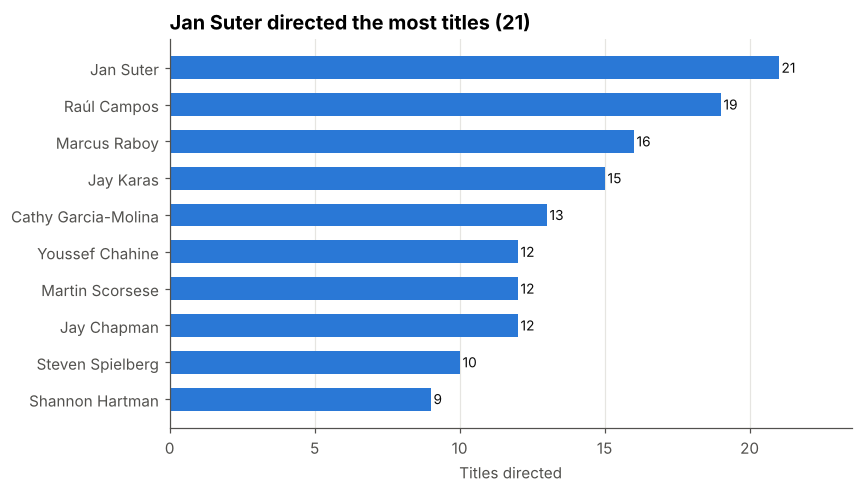

Titles with a listed director: 5,398 of 7,787
Movies with director listed: 97% | TV shows with director listed: 8%


In [14]:
dirs = (df[df["director"] != "Unknown"].assign(d=lambda x: x["director"].str.split(","))
          .explode("d"))
dirs["d"] = dirs["d"].str.strip()
top_d = dirs["d"].value_counts().head(10)[::-1]

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(top_d.index, top_d.values, color=BLUE, height=0.62)
for i, v in enumerate(top_d.values):
    ax.text(v + 0.1, i, str(v), va="center", color=INK, fontsize=9)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, top_d.max() * 1.12)
ax.set_xlabel("Titles directed")
ax.set_title(f"{top_d.index[-1]} directed the most titles ({top_d.iloc[-1]})")
save(fig, "10_top_directors"); plt.show()

print(f"Titles with a listed director: {(df['director'] != 'Unknown').sum():,} of {len(df):,}")
print("Movies with director listed: {:.0%} | TV shows with director listed: {:.0%}".format(
    (movies["director"] != "Unknown").mean(), (tv["director"] != "Unknown").mean()))

### 3.10 What does each country\'s catalogue lean on?

The two regional labels "International Movies" and "International TV Shows" are left out here, since they only say "not from the US" and hide the real genres.

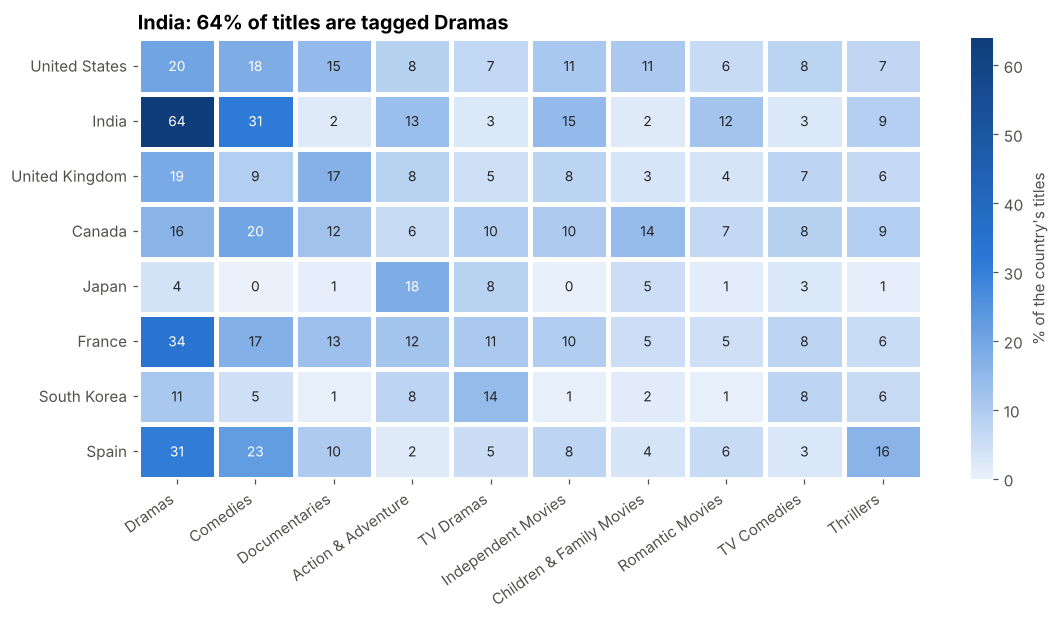

In [15]:
top8 = vc.head(8).index.tolist()
g_top = (genres[~genres["genre"].isin(region_tags)]["genre"].value_counts().head(10).index.tolist())
sub = genres[genres["primary_country"].isin(top8) & genres["genre"].isin(g_top)]
mat = pd.crosstab(sub["primary_country"], sub["genre"]).reindex(index=top8, columns=g_top, fill_value=0)
mat_pct = mat.div(vc.reindex(top8), axis=0) * 100

fig, ax = plt.subplots(figsize=(11.5, 5.2))
sns.heatmap(mat_pct, annot=True, fmt=".0f", cmap=SEQ, linewidths=2, linecolor="white",
            cbar_kws={"label": "% of the country's titles"}, annot_kws={"fontsize": 9}, ax=ax)
ax.grid(False)
stack = mat_pct.stack()
c_top, g_name = stack.idxmax()
ax.set_title(f"{c_top}: {stack.max():.0f}% of titles are tagged {g_name}")
ax.set_xlabel(""); ax.set_ylabel("")
plt.xticks(rotation=35, ha="right")
save(fig, "11_country_genre_heatmap"); plt.show()

### 3.11 India compared with the other big contributors

India titles: 956 (13% of titles with a known country)
Movies: 883 (92%) | TV shows: 73
Top genres in India (excluding the International labels):
genre
Dramas                611
Comedies              300
Independent Movies    140
Action & Adventure    127
Romantic Movies       113


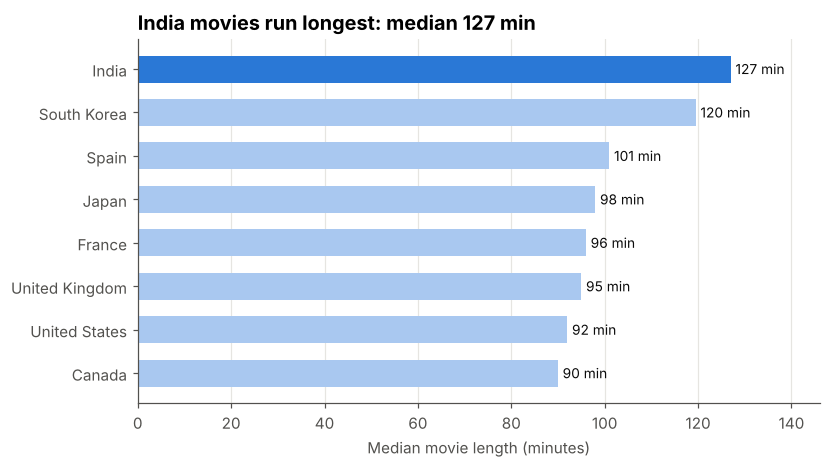

Indian movie median runtime vs all other top-8 countries combined: 127 vs 93 min


In [16]:
india = df[df["primary_country"] == "India"]
ind_movies = india[india["type"] == "Movie"]
non_int = genres[(genres["primary_country"] == "India") & (~genres["genre"].isin(region_tags))]

print(f"India titles: {len(india):,} ({len(india) / len(known):.0%} of titles with a known country)")
print(f"Movies: {len(ind_movies):,} ({len(ind_movies) / len(india):.0%}) | TV shows: {len(india) - len(ind_movies):,}")
print("Top genres in India (excluding the International labels):")
print(non_int["genre"].value_counts().head(5).to_string())

mv = df[(df["type"] == "Movie") & (df["primary_country"].isin(top8))]
rt = mv.groupby("primary_country")["minutes"].median().sort_values()

fig, ax = plt.subplots(figsize=(8, 4.3))
colors = [BLUE if c == "India" else LIGHT_BLUE for c in rt.index]
ax.barh(rt.index, rt.values, color=colors, height=0.62)
for i, v in enumerate(rt.values):
    ax.text(v + 1, i, f"{v:.0f} min", va="center", color=INK, fontsize=9)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, rt.max() * 1.15)
ax.set_xlabel("Median movie length (minutes)")
ax.set_title(f"{rt.index[-1]} movies run longest: median {rt.iloc[-1]:.0f} min")
save(fig, "12_runtime_by_country"); plt.show()

print("Indian movie median runtime vs all other top-8 countries combined:",
      f"{ind_movies['minutes'].median():.0f} vs {mv[mv['primary_country'] != 'India']['minutes'].median():.0f} min")

## 4. Key numbers

In [17]:
summary = {
    "Titles analysed": f"{len(df):,}",
    "Movies / TV shows": f"{share['Movie']:.0%} / {share['TV Show']:.0%}",
    "Peak year for additions": f"{peak_year} ({total_added[peak_year]:,} titles)",
    "Released 2015 or later": f"{recent_share:.0%}",
    "Top country (known)": f"{top_c.index[0]} ({top_c.iloc[0]:,}, {top_c.iloc[0] / len(known):.0%})",
    "Top 3 countries share": f"{top_c.head(3).sum() / len(known):.0%}",
    "Adult-rated: movies / TV": f"{aud.loc['Adults', 'Movie']:.0f}% / {aud.loc['Adults', 'TV Show']:.0f}%",
    "Median movie length": f"{med:.0f} min",
    "TV shows with one season": f"{one_season:.0%}",
    "Busiest / quietest month": f"{top_m} / {low_m}",
    "Added within 2 years of release": f"{within2:.0%}",
    "Top director": f"{top_d.index[-1]} ({top_d.iloc[-1]} titles)",
    "Strongest country-genre cell": f"{c_top}, {g_name} ({stack.max():.0f}%)",
    "Longest median runtime (top 8)": f"{rt.index[-1]} ({rt.iloc[-1]:.0f} min)",
}
pd.Series(summary, name="value").to_frame()

,value
Titles analysed,"7,787"
Movies / TV shows,69% / 31%
Peak year for additions,"2019 (2,153 titles)"
Released 2015 or later,70%
Top country (known),"United States (2,883, 40%)"
Top 3 countries share,61%
Adult-rated: movies / TV,47% / 42%
Median movie length,98 min
TV shows with one season,67%
Busiest / quietest month,December / February


## 5. Insights

**What the data says**

1. **Movies dominate, TV is the growing side.** 69% of the 7,787 titles are movies (5,377) and 31% are TV shows (2,410). In 2020, movie additions fell 12% from 2019 (1,497 to 1,312) while TV additions rose 6% (656 to 697).
2. **The catalogue grew very fast between 2016 and 2019.** Titles added per year went from 443 in 2016 to 2,153 in 2019, about 4.9 times more. 2020 was slightly lower at 2,009 (down 7%).
3. **It is a recent catalogue.** 70% of titles were released in 2015 or later, and only 5.8% before 2000. 64% arrived on Netflix within two years of release; the median movie arrives 1 year after release and the median TV show in its release year.
4. **Three countries make up 61% of titles with a known country.** The United States has 2,883 titles (40%), India 956 (13%) and the United Kingdom 577. Japan and South Korea contribute mostly TV shows, while India is almost all movies.
5. **Drama and comedy lead everywhere.** Dramas (2,106) and Comedies (1,471) are the top movie genres; TV Dramas (704), TV Comedies (525) and Crime TV Shows (427) lead on the TV side. The "International" labels (2,437 movie tags and 1,199 TV tags) show how much of the catalogue is made outside the US.
6. **The catalogue skews adult.** Adult ratings (TV-MA, R, NC-17) cover 47% of movies and 42% of TV shows.
7. **Movies are standard length, shows are short-lived.** The median movie runs 98 minutes (31% are under 90 minutes, only 4.2% over 150). 67% of TV shows have just one season, and the longest has 16.
8. **Releases cluster around the year end.** December (833 titles) is the busiest month and February (472) the quietest, with October to January all strong.

**India lens**

- India is the second-largest contributor with 956 titles, and 92% of them are movies.
- 64% of Indian titles are tagged Drama and 31% Comedy, a much stronger drama focus than the US (20%).
- Indian movies run longer: a median of 127 minutes versus 93 for the other top-8 countries.

**Limitations to keep in mind**

- The data is a snapshot taken in January 2021, so 2021 is left out of the yearly trends.
- The dataset only holds titles that were on Netflix at that time, so "added per year" counts titles still in the catalogue, not everything ever added.
- Country analysis uses the first listed country; co-productions are counted once, under that country.
- A title can carry several genres, so genre counts add up to more than the number of titles.
- 31% of titles have no listed director (mostly TV shows, where only 8% have one), so the director ranking effectively covers movies only.
- The analysis is descriptive. It shows what the catalogue looks like, not why.

**Possible next steps**

- Predict whether a title is a movie or a TV show, or its audience rating, from its description with text features (TF-IDF) and a classifier.
- Cluster titles by description to find content groups beyond the official genres.
- Add IMDb ratings to study whether more popular genres are also better rated.